# Proyek Analisis Data: Beijing Multi-Site Air Quality (PRSA)
- **Nama:** Muhammad Hanif Zidan
- **Email:** zidanhanif318@gmail.com
- **ID Dicoding:** DS128B6Y1174

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Stasiun mana yang memiliki rata-rata PM2.5 tertinggi dan terendah di antara 12 stasiun pemantauan di Beijing selama 1 Maret 2013 - 28 Februari 2017, dan berapa persentase hari dengan rata-rata PM2.5 harian di atas 75 µg/m³ (standar harian China) pada setiap stasiun, sehingga wilayah prioritas pengendalian polusi dapat ditentukan?
- **Pertanyaan 2:** Pada bulan dan jam berapa rata-rata PM2.5 seluruh stasiun mencapai nilai tertinggi selama 1 Maret 2013 - 28 Februari 2017, dan berapa koefisien korelasi PM2.5 dengan kecepatan angin dan suhu, sehingga jadwal peringatan dini polusi dapat disusun?
- **Pertanyaan 3:** Bagaimana perubahan rata-rata PM2.5 pada setiap stasiun untuk periode 12 bulan (Maret - Februari) dari 2013/2014 hingga 2016/2017, berapa persentase perubahannya, dan stasiun mana yang mengalami penurunan terbesar maupun terkecil, sehingga perkembangan kualitas udara di setiap stasiun dapat dievaluasi?

**Penjelasan SMART:**
- **Specific:** tiap pertanyaan fokus pada satu tujuan, yaitu PM2.5 per stasiun (P1), pola waktu dan faktor cuaca (P2), serta perubahan antarperiode (P3).
- **Measurable:** dijawab dengan angka: rata-rata µg/m³, persentase hari > 75 µg/m³, koefisien korelasi, dan persentase perubahan.
- **Action-oriented:** hasilnya menentukan wilayah prioritas intervensi (P1), jadwal peringatan dini (P2), dan evaluasi upaya pengendalian polusi (P3).
- **Relevant:** sejalan dengan tujuan proyek, yaitu memahami kualitas udara Beijing untuk mendukung keputusan kesehatan masyarakat.
- **Time-bound:** seluruhnya dibatasi pada 1 Maret 2013 - 28 Februari 2017 (P3 per periode 12 bulan Maret - Februari).

## Import Semua Packages/Library yang Digunakan

In [29]:
import glob
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

## Data Wrangling

### Gathering Data

#### Load data kualitas udara 12 stasiun

In [4]:
# Memuat 12 file CSV (satu file per stasiun) lalu menggabungkannya menjadi satu DataFrame
files = sorted(glob.glob("data/PRSA_Data_*.csv"))
print(f"Jumlah file ditemukan: {len(files)}")

df_raw = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
print(f"Ukuran data gabungan: {df_raw.shape}")
df_raw.head()

Jumlah file ditemukan: 12
Ukuran data gabungan: (420768, 18)


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


In [5]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    412029 non-null  float64
 6   PM10     414319 non-null  float64
 7   SO2      411747 non-null  float64
 8   NO2      408652 non-null  float64
 9   CO       400067 non-null  float64
 10  O3       407491 non-null  float64
 11  TEMP     420370 non-null  float64
 12  PRES     420375 non-null  float64
 13  DEWP     420365 non-null  float64
 14  RAIN     420378 non-null  float64
 15  wd       418946 non-null  object 
 16  WSPM     420450 non-null  float64
 17  station  420768 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 57.8+ MB


**Insight:**
- Data terdiri dari 12 file (1 file per stasiun) dengan total 420.768 baris dan 18 kolom: polutan (PM2.5, PM10, SO2, NO2, CO, O3), cuaca (TEMP, PRES, DEWP, RAIN, wd, WSPM), serta waktu dan nama stasiun.
- Data berbentuk deret waktu per jam dari 1 Maret 2013 sampai 28 Februari 2017.

### Assessing Data

#### Identifying missing value

In [6]:
# 1) Missing value
missing = pd.DataFrame({
    "jumlah_missing": df_raw.isna().sum(),
    "persen_missing": (df_raw.isna().mean() * 100).round(2)
})
missing[missing["jumlah_missing"] > 0].sort_values("jumlah_missing", ascending=False)

,jumlah_missing,persen_missing
CO,20701,4.92
O3,13277,3.16
NO2,12116,2.88
SO2,9021,2.14
PM2.5,8739,2.08
PM10,6449,1.53
wd,1822,0.43
DEWP,403,0.10
TEMP,398,0.09
PRES,393,0.09


#### Identifying duplicate data dan kelengkapan deret waktu

In [7]:
# 2) Duplicate data
print("Baris duplikat (seluruh kolom)        :", df_raw.duplicated().sum())
print("Duplikat kombinasi stasiun + waktu     :", df_raw.duplicated(subset=["station", "year", "month", "day", "hour"]).sum())

# Kelengkapan deret waktu: setiap stasiun seharusnya punya 1461 hari x 24 jam = 35064 baris
print("\nJumlah baris per stasiun:")
print(df_raw.groupby("station").size().to_string())

Baris duplikat (seluruh kolom)        : 0
Duplikat kombinasi stasiun + waktu     : 0

Jumlah baris per stasiun:
station
Aotizhongxin     35064
Changping        35064
Dingling         35064
Dongsi           35064
Guanyuan         35064
Gucheng          35064
Huairou          35064
Nongzhanguan     35064
Shunyi           35064
Tiantan          35064
Wanliu           35064
Wanshouxigong    35064


#### Identifying inaccurate value dan invalid value

In [8]:
# 3) Inaccurate value: PM2.5 adalah bagian dari PM10, sehingga PM2.5 tidak boleh > PM10
pm_tidak_valid = df_raw["PM2.5"] > df_raw["PM10"]
print("Baris dengan PM2.5 > PM10:", pm_tidak_valid.sum(), f"({pm_tidak_valid.mean()*100:.2f}%)")

# 4) Invalid value: konsentrasi polutan tidak boleh negatif
polutan = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]
print("\nJumlah nilai negatif per polutan:")
print((df_raw[polutan] < 0).sum().to_string())

Baris dengan PM2.5 > PM10: 21312 (5.07%)

Jumlah nilai negatif per polutan:
PM2.5    0
PM10     0
SO2      0
NO2      0
CO       0
O3       0


#### Identifying outlier

Batas atas IQR PM2.5 : 247.5 µg/m³
Jumlah outlier       : 19142 (4.55%)
Nilai maksimum       : 999.0


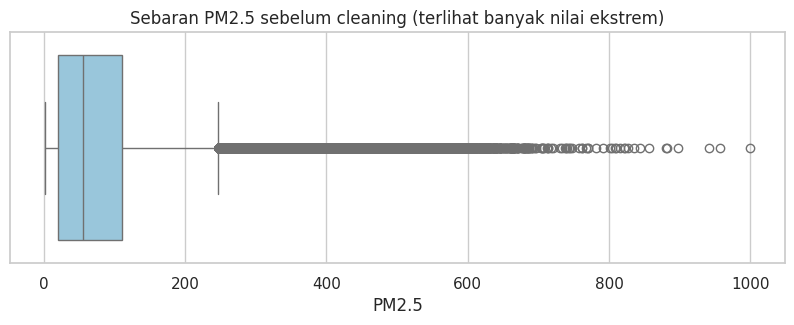

In [9]:
# 5) Outlier pada PM2.5 menggunakan metode IQR
q1, q3 = df_raw["PM2.5"].quantile([0.25, 0.75])
iqr = q3 - q1
batas_atas = q3 + 1.5 * iqr
n_outlier = (df_raw["PM2.5"] > batas_atas).sum()
print(f"Batas atas IQR PM2.5 : {batas_atas:.1f} µg/m³")
print(f"Jumlah outlier       : {n_outlier} ({n_outlier/len(df_raw)*100:.2f}%)")
print(f"Nilai maksimum       : {df_raw['PM2.5'].max()}")

fig, ax = plt.subplots(figsize=(10, 3))
sns.boxplot(x=df_raw["PM2.5"], ax=ax, color="#8ecae6")
ax.set_title("Sebaran PM2.5 sebelum cleaning (terlihat banyak nilai ekstrem)")
plt.show()

#### Identifying inconsistent value pada arah angin

In [10]:
# 6) Inconsistent / kualitas kolom kategorikal: arah angin (wd)
print("Missing pada kolom wd :", df_raw["wd"].isna().sum())
print("Kategori arah angin   :", sorted(df_raw["wd"].dropna().unique()))
print("Jumlah kategori       :", df_raw["wd"].nunique())

Missing pada kolom wd : 1822
Kategori arah angin   : ['E', 'ENE', 'ESE', 'N', 'NE', 'NNE', 'NNW', 'NW', 'S', 'SE', 'SSE', 'SSW', 'SW', 'W', 'WNW', 'WSW']
Jumlah kategori       : 16


**Steps to Take:**
- **Missing value** (CO 4,92%, O3 3,16%, NO2 2,88%, PM2.5 2,08%, dst.): interpolasi linear per stasiun untuk celah <= 6 jam, sisanya diisi median stasiun pada bulan yang sama. Kolom `wd` (kategorikal) diisi dengan forward-fill per stasiun.
- **Inaccurate value** (21.312 baris dengan PM2.5 > PM10): PM10 pada baris tersebut dikosongkan lalu diimputasi, karena PM2.5 adalah variabel utama analisis. Karena imputasi bisa menghasilkan PM10 < PM2.5 lagi, setelahnya PM10 dipastikan minimal sama dengan PM2.5.
- **Outlier** (4,55% data PM2.5 di atas batas IQR 247,5 µg/m³): dipertahankan karena merupakan kejadian polusi nyata, bukan kesalahan input. Analisis memakai rata-rata harian/bulanan dan median sebagai pembanding.
- **Duplicate** tidak ditemukan dan tiap stasiun memiliki 35.064 baris (lengkap), tidak ada nilai negatif (invalid), sehingga tidak ada tindakan khusus.
- Membuat kolom `datetime`, `periode` (Maret - Februari), dan `musim`; kolom `No` dibuang.

**Insight:**
- Missing value tersebar di semua kolom polutan dan cuaca, paling banyak di CO, sementara PM2.5 hanya 2,08%.
- Sekitar 5% baris memiliki PM2.5 > PM10, secara fisik tidak mungkin karena PM2.5 adalah bagian dari PM10, sehingga perlu penanganan.
- Distribusi PM2.5 sangat condong ke kanan: rata-rata (79,8) jauh di atas median (55), tanda adanya episode polusi berat.

### Cleaning Data

#### Membuat kolom datetime dan menghapus kolom tidak perlu

In [11]:
df = df_raw.copy()

# Membuat kolom datetime dari year, month, day, hour, lalu mengurutkan data per stasiun
df["datetime"] = pd.to_datetime(df[["year", "month", "day", "hour"]])
df = df.sort_values(["station", "datetime"]).reset_index(drop=True)

# Kolom "No" hanyalah nomor urut sehingga dibuang
df = df.drop(columns=["No"])
print("Rentang waktu:", df["datetime"].min(), "s.d.", df["datetime"].max())

Rentang waktu: 2013-03-01 00:00:00 s.d. 2017-02-28 23:00:00


#### Fixing inaccurate value (PM2.5 > PM10)

In [12]:
# Inaccurate value: pada baris PM2.5 > PM10, nilai PM10 dianggap tidak akurat
# (PM2.5 adalah variabel utama analisis, sehingga dipertahankan). PM10 dikosongkan lalu diimputasi bersama missing value lain.
mask = df["PM2.5"] > df["PM10"]
df.loc[mask, "PM10"] = np.nan
print("Nilai PM10 yang dikosongkan:", mask.sum())

Nilai PM10 yang dikosongkan: 21312


#### Fixing missing value

In [13]:
kolom_numerik = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM"]

# Tahap 1: interpolasi linear per stasiun untuk celah pendek (maksimal 6 jam berturut-turut)
df[kolom_numerik] = (
    df.groupby("station")[kolom_numerik]
      .transform(lambda s: s.interpolate(method="linear", limit=6, limit_direction="both"))
)

# Tahap 2: sisa missing (celah panjang) diisi median stasiun pada bulan yang sama
df["month_tmp"] = df["datetime"].dt.month
for col in kolom_numerik:
    df[col] = df[col].fillna(df.groupby(["station", "month_tmp"])[col].transform("median"))
df = df.drop(columns="month_tmp")

# Arah angin (kategorikal): forward-fill per stasiun, sisanya diisi modus
df["wd"] = df.groupby("station")["wd"].ffill().bfill()

print("Total missing value setelah cleaning:", df.isna().sum().sum())

Total missing value setelah cleaning: 0


In [27]:
# Setelah imputasi, nilai PM10 hasil interpolasi/median bisa kembali lebih kecil dari PM2.5.
# PM10 mencakup PM2.5, sehingga PM10 tidak boleh lebih kecil dari PM2.5 -> PM10 dinaikkan ke nilai PM2.5 pada baris tersebut.
n_sebelum = (df["PM10"] < df["PM2.5"]).sum()
df["PM10"] = df[["PM10", "PM2.5"]].max(axis=1)
print("Baris PM2.5 > PM10 sebelum perbaikan :", n_sebelum)
print("Baris PM2.5 > PM10 setelah perbaikan :", (df["PM2.5"] > df["PM10"]).sum())

Baris PM2.5 > PM10 sebelum perbaikan : 11614
Baris PM2.5 > PM10 setelah perbaikan : 0


#### Handling outlier dan pengecekan duplikat

In [14]:
# Outlier: nilai ekstrem PM2.5 merupakan kejadian polusi nyata (mis. episode smog Beijing, nilai tertinggi 999 = batas alat ukur),
# sehingga TIDAK dihapus. Agar tidak bias, analisis lebih banyak memakai rata-rata harian/bulanan dan median sebagai pembanding.
print("PM2.5 pada batas alat ukur (>= 999):", (df["PM2.5"] >= 999).sum(), "baris")
print("Duplikat setelah cleaning:", df.duplicated().sum())
df[["PM2.5", "PM10"]].describe().round(1)

PM2.5 pada batas alat ukur (>= 999): 1 baris
Duplikat setelah cleaning: 0


,PM2.5,PM10
count,420768.0,420768.0
mean,79.7,105.5
std,80.8,92.0
min,2.0,2.0
25%,21.0,37.0
50%,55.0,83.0
75%,111.0,146.0
max,999.0,999.0


#### Feature engineering (periode 12 bulan dan musim)

In [15]:
# Feature engineering untuk kebutuhan analisis
df["date"] = df["datetime"].dt.date
df["year"] = df["datetime"].dt.year
df["month"] = df["datetime"].dt.month
df["hour"] = df["datetime"].dt.hour

# Periode 12 bulan (Maret - Februari) agar perbandingan antartahun adil karena data mulai 1 Maret 2013 dan berakhir 28 Februari 2017
df["periode"] = np.where(
    df["month"] >= 3,
    df["year"].astype(str) + "/" + (df["year"] + 1).astype(str),
    (df["year"] - 1).astype(str) + "/" + df["year"].astype(str),
)

# Musim di Beijing
peta_musim = {12: "Dingin", 1: "Dingin", 2: "Dingin", 3: "Semi", 4: "Semi", 5: "Semi",
              6: "Panas", 7: "Panas", 8: "Panas", 9: "Gugur", 10: "Gugur", 11: "Gugur"}
df["musim"] = df["month"].map(peta_musim)

print(df["periode"].value_counts().sort_index().to_string())
df.head()

periode
2013/2014    105120
2014/2015    105120
2015/2016    105408
2016/2017    105120


,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,datetime,date,periode,musim
0,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01 00:00:00,2013-03-01,2013/2014,Semi
1,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,2013-03-01 01:00:00,2013-03-01,2013/2014,Semi
2,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,2013-03-01 02:00:00,2013-03-01,2013/2014,Semi
3,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin,2013-03-01 03:00:00,2013-03-01,2013/2014,Semi
4,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin,2013-03-01 04:00:00,2013-03-01,2013/2014,Semi


In [16]:
# Menyimpan data bersih (digunakan oleh dashboard Streamlit)
os.makedirs("dashboard", exist_ok=True)
kolom_dashboard = ["datetime", "station", "PM2.5", "TEMP", "PRES", "DEWP", "RAIN", "wd", "WSPM", "periode", "musim"]
df[kolom_dashboard].round(1).to_csv("dashboard/main_data.csv", index=False)
print("Tersimpan:", df[kolom_dashboard].shape)

Tersimpan: (420768, 11)


**Insight:**
- Setelah cleaning tidak ada lagi missing value maupun duplikat, dan 4 periode 12 bulan (Mar - Feb) memiliki jumlah data yang seimbang sehingga bisa dibandingkan.
- Data bersih disimpan ke `dashboard/main_data.csv` untuk dashboard Streamlit.

## Exploratory Data Analysis (EDA)

### Explore ringkasan statistik

In [17]:
df[kolom_numerik].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
PM2.5,420768.0,79.73,80.84,2.00,21.0,55.0,111.00,999.0
PM10,420768.0,105.55,91.99,2.00,37.0,83.0,146.00,999.0
SO2,420768.0,15.82,21.73,0.29,3.0,7.0,19.14,500.0
NO2,420768.0,50.48,35.05,1.03,23.0,43.0,71.00,290.0
CO,420768.0,1230.55,1159.35,100.00,500.0,900.0,1500.00,10000.0
O3,420768.0,56.92,56.51,0.21,10.0,44.0,81.00,1071.0
TEMP,420768.0,13.53,11.44,-19.90,3.1,14.5,23.30,41.6
PRES,420768.0,1010.75,10.47,982.40,1002.3,1010.4,1019.00,1042.8
DEWP,420768.0,2.48,13.80,-43.40,-8.9,3.0,15.10,29.1
RAIN,420768.0,0.06,0.82,0.00,0.0,0.0,0.00,72.5


### Explore PM2.5 per stasiun (Pertanyaan 1)

In [18]:
# Rata-rata harian PM2.5 per stasiun
harian = (df.groupby(["station", "date"])["PM2.5"].mean().reset_index(name="pm25_harian"))

NAAQS_HARIAN = 75   # Standar kualitas udara China Grade II (24 jam)
WHO_HARIAN = 15     # Pedoman WHO 2021 (24 jam)

ringkasan_stasiun = harian.groupby("station")["pm25_harian"].agg(
    rata_rata="mean", median="median", maks="max"
)
ringkasan_stasiun["persen_hari_>75"] = harian.groupby("station")["pm25_harian"].apply(lambda s: (s > NAAQS_HARIAN).mean() * 100)
ringkasan_stasiun["persen_hari_>15_WHO"] = harian.groupby("station")["pm25_harian"].apply(lambda s: (s > WHO_HARIAN).mean() * 100)
ringkasan_stasiun = ringkasan_stasiun.sort_values("rata_rata", ascending=False).round(2)
ringkasan_stasiun

,rata_rata,median,maks,persen_hari_>75,persen_hari_>15_WHO
station,,,,,
Dongsi,85.92,65.92,567.42,43.26,91.99
Nongzhanguan,85.11,63.54,516.06,42.78,91.31
Wanshouxigong,84.96,64.54,536.62,42.71,92.47
Gucheng,83.93,65.46,519.75,42.98,92.40
Wanliu,83.45,64.62,481.29,42.78,92.06
Guanyuan,82.83,63.83,536.08,42.09,92.54
Aotizhongxin,82.57,62.38,512.29,41.82,91.85
Tiantan,81.99,62.67,499.33,41.27,91.79
Shunyi,79.49,60.00,514.62,40.66,91.38


In [19]:
selisih = ringkasan_stasiun["rata_rata"].max() - ringkasan_stasiun["rata_rata"].min()
print("Tertinggi :", ringkasan_stasiun["rata_rata"].idxmax(), round(ringkasan_stasiun["rata_rata"].max(), 2))
print("Terendah  :", ringkasan_stasiun["rata_rata"].idxmin(), round(ringkasan_stasiun["rata_rata"].min(), 2))
print("Selisih   :", round(selisih, 2), "µg/m³")
print("Rata-rata seluruh stasiun:", round(df["PM2.5"].mean(), 2))

Tertinggi : Dongsi 85.92
Terendah  : Dingling 66.21
Selisih   : 19.71 µg/m³
Rata-rata seluruh stasiun: 79.73


### Explore pola bulan, jam, musim, dan hubungan dengan cuaca (Pertanyaan 2)

In [20]:
# Pola per bulan, per jam, dan per musim (seluruh stasiun)
per_bulan = df.groupby("month")["PM2.5"].mean().round(2)
per_jam = df.groupby("hour")["PM2.5"].mean().round(2)
per_musim = df.groupby("musim")["PM2.5"].agg(["mean", "median"]).round(2).sort_values("mean", ascending=False)

print("Rata-rata PM2.5 per bulan:")
print(per_bulan.to_string())
print("\nBulan tertinggi:", per_bulan.idxmax(), "| terendah:", per_bulan.idxmin())
print("\nJam tertinggi:", per_jam.idxmax(), "| terendah:", per_jam.idxmin())
print("\nPer musim:")
print(per_musim.to_string())

Rata-rata PM2.5 per bulan:
month
1      93.69
2      89.13
3      94.59
4      73.00
5      63.08
6      68.72
7      71.53
8      53.41
9      61.23
10     91.32
11     93.31
12    103.86

Bulan tertinggi: 12 | terendah: 8

Jam tertinggi: 22 | terendah: 7

Per musim:
         mean  median
musim                
Dingin  95.75    57.0
Gugur   82.06    55.0
Semi    76.93    58.0
Panas   64.51    51.0


In [21]:
# Korelasi (Pearson) PM2.5 dengan variabel cuaca
kolom_cuaca = ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
korelasi = df[["PM2.5"] + kolom_cuaca].corr()["PM2.5"].drop("PM2.5").sort_values()
print(korelasi.round(3).to_string())

# PM2.5 berdasarkan arah angin
print("\nRata-rata PM2.5 menurut arah angin (5 tertinggi & 3 terendah):")
wd_mean = df.groupby("wd")["PM2.5"].mean().sort_values(ascending=False).round(1)
print(pd.concat([wd_mean.head(5), wd_mean.tail(3)]).to_string())

WSPM   -0.271
TEMP   -0.132
RAIN   -0.014
PRES    0.020
DEWP    0.113

Rata-rata PM2.5 menurut arah angin (5 tertinggi & 3 terendah):
wd
ESE    101.7
E      101.4
ENE     97.7
SE      96.6
SSE     93.3
WNW     56.8
NNW     53.8
NW      51.7


### Explore tren per periode 12 bulan (Pertanyaan 3)

In [22]:
# Rata-rata PM2.5 per periode 12 bulan (Maret - Februari)
per_periode = df.groupby("periode")["PM2.5"].mean().round(2)
print(per_periode.to_string())

per_periode_stasiun = df.pivot_table(index="station", columns="periode", values="PM2.5", aggfunc="mean").round(2)
per_periode_stasiun["perubahan_%"] = ((per_periode_stasiun.iloc[:, -1] - per_periode_stasiun.iloc[:, 0]) / per_periode_stasiun.iloc[:, 0] * 100).round(2)
per_periode_stasiun.sort_values("perubahan_%")

periode
2013/2014    86.95
2014/2015    81.23
2015/2016    72.89
2016/2017    77.87


periode,2013/2014,2014/2015,2015/2016,2016/2017,perubahan_%
station,,,,,
Wanliu,98.49,84.06,73.60,77.68,-21.13
Changping,79.24,76.08,61.76,67.04,-15.40
Huairou,75.61,71.03,65.35,65.00,-14.03
Dingling,72.48,70.53,58.11,63.75,-12.04
Tiantan,89.26,83.05,75.49,80.20,-10.15
Aotizhongxin,88.69,84.81,76.59,80.21,-9.56
Nongzhanguan,91.76,87.76,77.70,83.25,-9.27
Shunyi,84.56,80.18,75.70,77.54,-8.30
Wanshouxigong,92.25,84.79,77.49,85.33,-7.50


**Insight:**
- Dongsi memiliki rata-rata PM2.5 tertinggi (85,9 µg/m³) dan Dingling terendah (66,2 µg/m³), selisih sekitar 19,7 µg/m³. Semua stasiun berada jauh di atas standar tahunan China (35 µg/m³).
- Desember adalah bulan terburuk (103,9) dan Agustus terbaik (53,4); musim dingin rata-rata 95,8 vs musim panas 64,5. Jam puncak sekitar pukul 22 (88,9) dan terendah pukul 07 (73,3).
- Kecepatan angin berkorelasi negatif paling kuat dengan PM2.5 (r = -0,27), suhu -0,13. Angin dari arah timur-tenggara (ESE, E, ENE) membawa PM2.5 tertinggi (98-102), angin barat laut (NW, NNW) terendah (52-54).
- Rata-rata PM2.5 turun dari 86,95 (2013/2014) ke 72,89 (2015/2016), lalu naik lagi ke 77,87 (2016/2017).

## Visualization & Explanatory Analysis

### Pertanyaan 1: Stasiun mana yang memiliki rata-rata PM2.5 tertinggi dan terendah di antara 12 stasiun pemantauan di Beijing selama 1 Maret 2013 - 28 Februari 2017, dan berapa persentase hari dengan rata-rata PM2.5 harian di atas 75 µg/m³ (standar harian China) pada setiap stasiun, sehingga wilayah prioritas pengendalian polusi dapat ditentukan?

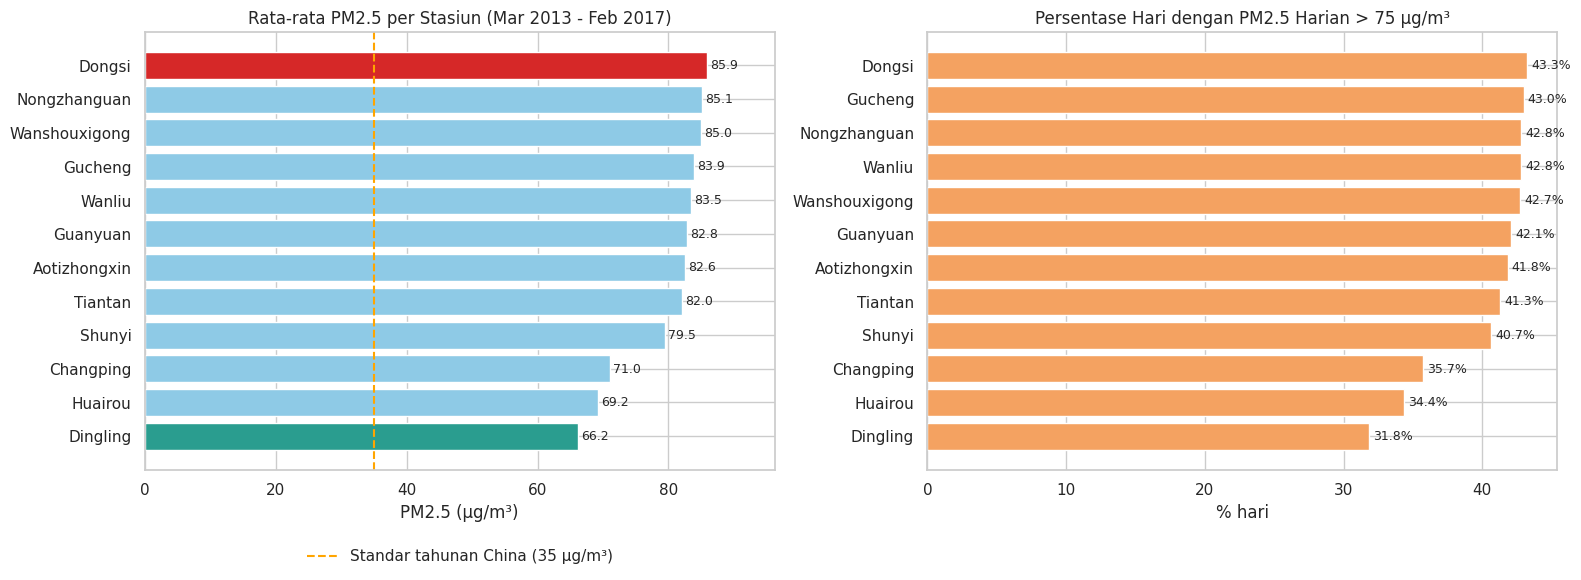

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

urut = ringkasan_stasiun.sort_values("rata_rata", ascending=True)
warna = ["#d62828" if s == urut["rata_rata"].idxmax() else "#2a9d8f" if s == urut["rata_rata"].idxmin() else "#8ecae6" for s in urut.index]

axes[0].barh(urut.index, urut["rata_rata"], color=warna)
axes[0].axvline(35, color="orange", linestyle="--", label="Standar tahunan China (35 µg/m³)")
for i, v in enumerate(urut["rata_rata"]):
    axes[0].text(v + 0.5, i, f"{v:.1f}", va="center", fontsize=9)
axes[0].set_title("Rata-rata PM2.5 per Stasiun (Mar 2013 - Feb 2017)")
axes[0].set_xlabel("PM2.5 (µg/m³)")
axes[0].set_xlim(0, urut["rata_rata"].max() * 1.12)
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), frameon=False)

urut2 = ringkasan_stasiun.sort_values("persen_hari_>75", ascending=True)
axes[1].barh(urut2.index, urut2["persen_hari_>75"], color="#f4a261")
for i, v in enumerate(urut2["persen_hari_>75"]):
    axes[1].text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=9)
axes[1].set_title("Persentase Hari dengan PM2.5 Harian > 75 µg/m³")
axes[1].set_xlabel("% hari")

plt.tight_layout()
plt.show()

### Pertanyaan 2: Pada bulan dan jam berapa rata-rata PM2.5 seluruh stasiun mencapai nilai tertinggi selama 1 Maret 2013 - 28 Februari 2017, dan berapa koefisien korelasi PM2.5 dengan kecepatan angin dan suhu, sehingga jadwal peringatan dini polusi dapat disusun?

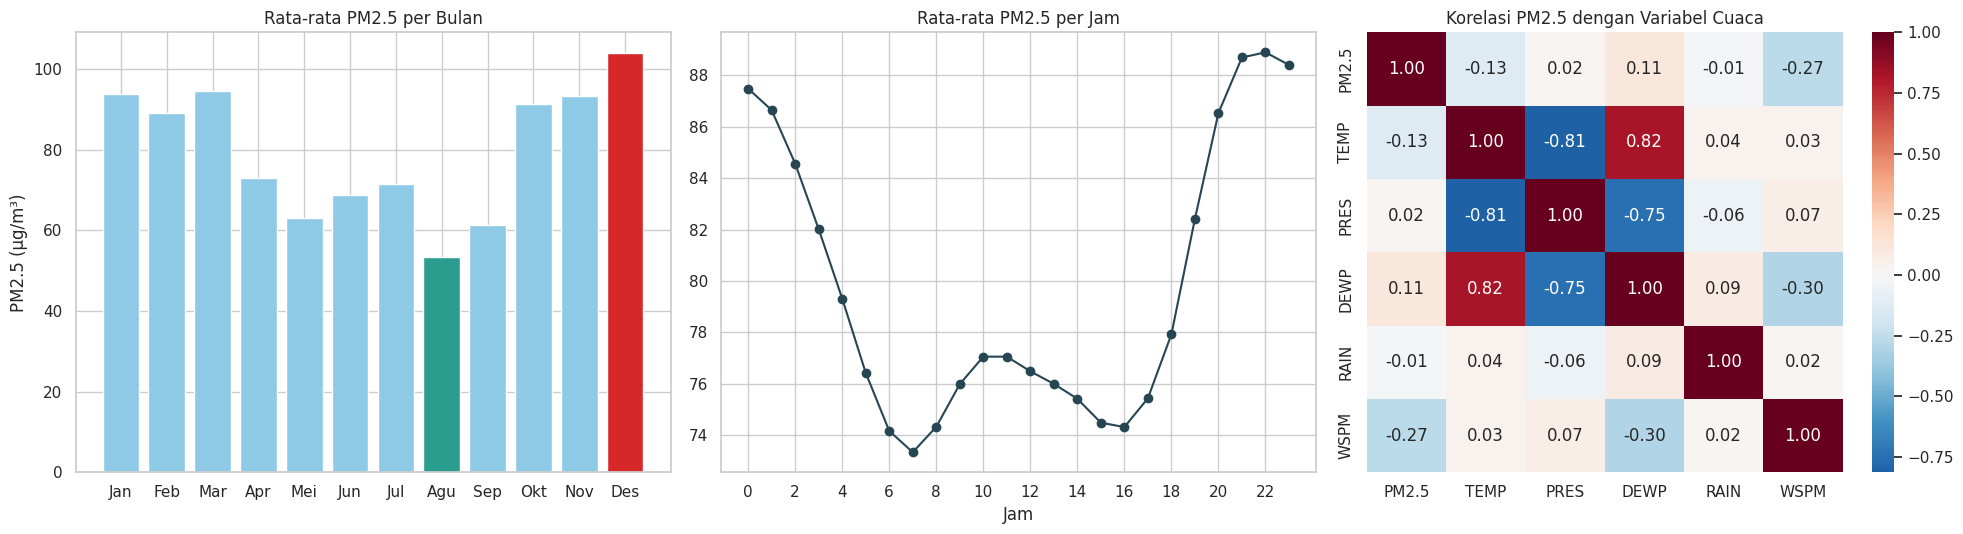

In [24]:
nama_bulan = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

# (a) Per bulan
warna_bulan = ["#d62828" if m == per_bulan.idxmax() else "#2a9d8f" if m == per_bulan.idxmin() else "#8ecae6" for m in per_bulan.index]
axes[0].bar(nama_bulan, per_bulan.values, color=warna_bulan)
axes[0].set_title("Rata-rata PM2.5 per Bulan")
axes[0].set_ylabel("PM2.5 (µg/m³)")

# (b) Per jam
axes[1].plot(per_jam.index, per_jam.values, marker="o", color="#264653")
axes[1].set_xticks(range(0, 24, 2))
axes[1].set_title("Rata-rata PM2.5 per Jam")
axes[1].set_xlabel("Jam")

# (c) Korelasi dengan cuaca
sns.heatmap(df[["PM2.5"] + kolom_cuaca].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[2])
axes[2].set_title("Korelasi PM2.5 dengan Variabel Cuaca")

plt.tight_layout()
plt.show()

### Pertanyaan 3: Bagaimana perubahan rata-rata PM2.5 pada setiap stasiun untuk periode 12 bulan (Maret - Februari) dari 2013/2014 hingga 2016/2017, berapa persentase perubahannya, dan stasiun mana yang mengalami penurunan terbesar maupun terkecil, sehingga perkembangan kualitas udara di setiap stasiun dapat dievaluasi?

Penurunan terbesar: Wanliu (-21.13%)
Penurunan terkecil: Gucheng (-5.83%)


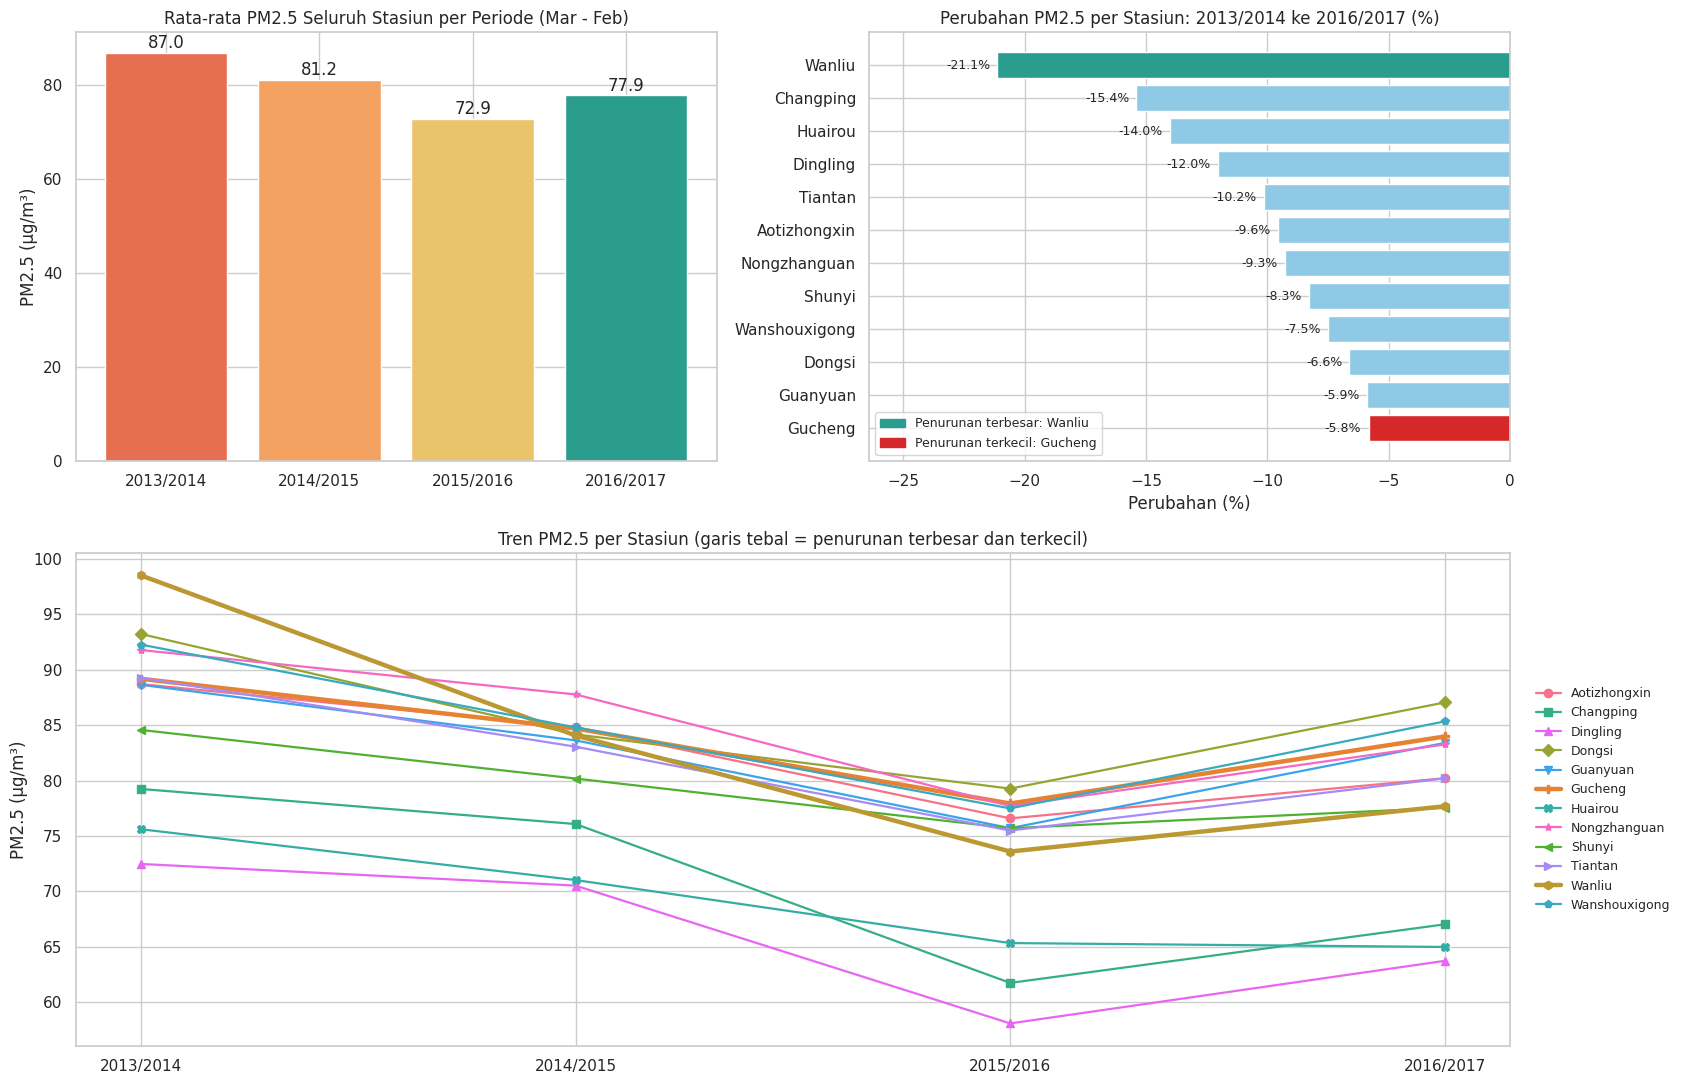

In [30]:
# Persentase perubahan periode pertama (2013/2014) ke periode terakhir (2016/2017) per stasiun
perubahan = per_periode_stasiun["perubahan_%"].sort_values(ascending=False)
turun_terbesar = perubahan.idxmin()
turun_terkecil = perubahan.idxmax()
print(f"Penurunan terbesar: {turun_terbesar} ({perubahan.min():.2f}%)")
print(f"Penurunan terkecil: {turun_terkecil} ({perubahan.max():.2f}%)")

fig = plt.figure(figsize=(17, 11))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.15])
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, :])

# (a) Rata-rata seluruh stasiun per periode
ax1.bar(per_periode.index, per_periode.values, color=["#e76f51", "#f4a261", "#e9c46a", "#2a9d8f"])
for i, v in enumerate(per_periode.values):
    ax1.text(i, v + 1, f"{v:.1f}", ha="center")
ax1.set_title("Rata-rata PM2.5 Seluruh Stasiun per Periode (Mar - Feb)")
ax1.set_ylabel("PM2.5 (µg/m³)")

# (b) Persentase perubahan per stasiun (hijau = penurunan terbesar, merah = penurunan terkecil)
warna_bar = ["#2a9d8f" if s == turun_terbesar else "#d62828" if s == turun_terkecil else "#8ecae6" for s in perubahan.index]
ax2.barh(perubahan.index, perubahan.values, color=warna_bar)
for i, v in enumerate(perubahan.values):
    ax2.text(v - 0.3, i, f"{v:.1f}%", va="center", ha="right", fontsize=9)
ax2.set_xlim(perubahan.min() * 1.25, 0)
ax2.set_title("Perubahan PM2.5 per Stasiun: 2013/2014 ke 2016/2017 (%)")
ax2.set_xlabel("Perubahan (%)")
ax2.legend(handles=[Patch(color="#2a9d8f", label=f"Penurunan terbesar: {turun_terbesar}"),
                    Patch(color="#d62828", label=f"Penurunan terkecil: {turun_terkecil}")],
           loc="lower left", frameon=True, fontsize=9)

# (c) Tren per stasiun: 12 warna berbeda + marker berbeda agar setiap garis dapat dibedakan
tren = per_periode_stasiun.drop(columns="perubahan_%")
paleta = sns.color_palette("husl", len(tren))
warna_garis = [paleta[(i * 5) % len(tren)] for i in range(len(tren))]  # loncat 5 warna agar stasiun bersebelahan tidak bernuansa mirip
marker_garis = ["o", "s", "^", "D", "v", "P", "X", "*", "<", ">", "h", "p"]
for i, stasiun in enumerate(tren.index):
    tebal = 3.2 if stasiun in (turun_terbesar, turun_terkecil) else 1.6
    ax3.plot(tren.columns, tren.loc[stasiun], marker=marker_garis[i], color=warna_garis[i], linewidth=tebal, label=stasiun)
ax3.set_title("Tren PM2.5 per Stasiun (garis tebal = penurunan terbesar dan terkecil)")
ax3.set_ylabel("PM2.5 (µg/m³)")
ax3.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=9, frameon=False)

plt.tight_layout()
plt.show()

**Insight:**
- Pertanyaan 1: stasiun pusat kota (Dongsi, Nongzhanguan, Wanshouxigong, Gucheng) punya PM2.5 tertinggi dengan ~43% hari melewati 75 µg/m³, sedangkan stasiun pinggiran (Dingling, Huairou, Changping) lebih bersih (32-36% hari).
- Pertanyaan 2: PM2.5 mencapai puncak pada bulan dingin (Desember, Maret, Januari) dan malam hari (sekitar 21.00-23.00). Angin kencang membersihkan polutan (korelasi negatif).
- Pertanyaan 3: tren turun dari 2013/2014 ke 2015/2016, namun rebound di 2016/2017. Wanliu membaik paling besar (-21,1%) dan Gucheng paling kecil (-5,8%).

## Analisis Lanjutan (Opsional)

Teknik **binning** (pengelompokan manual): PM2.5 dikelompokkan ke dalam kategori kualitas udara (berdasarkan ambang AQI China) dan kecepatan angin dikelompokkan menjadi 4 kelas.

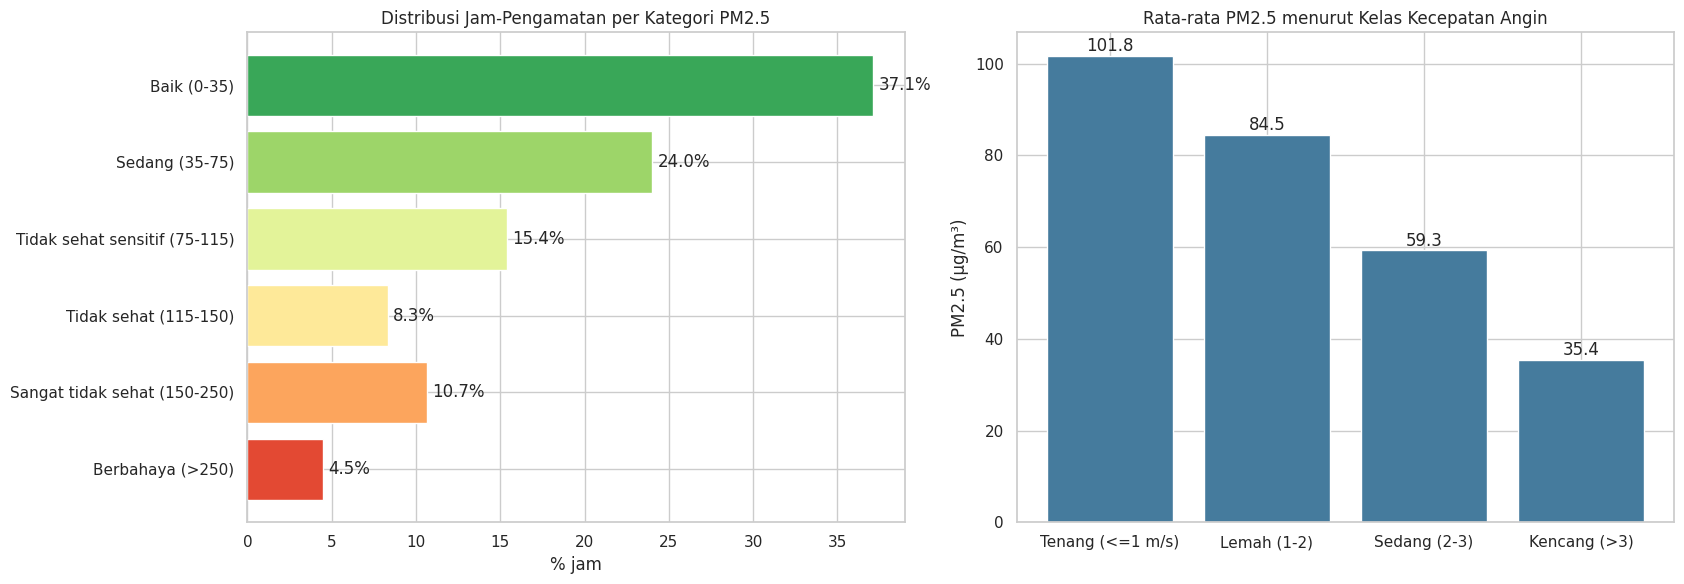

Persentase jam pada kategori 'Sangat tidak sehat' ke atas: 15.13 %
Rata-rata PM2.5 menurut kelas angin:
kelas_angin
Tenang (<=1 m/s)    101.8
Lemah (1-2)          84.5
Sedang (2-3)         59.3
Kencang (>3)         35.4


In [26]:
# Analisis lanjutan: binning (pengelompokan manual) kategori kualitas udara & kecepatan angin
batas_kategori = [0, 35, 75, 115, 150, 250, np.inf]
label_kategori = ["Baik (0-35)", "Sedang (35-75)", "Tidak sehat sensitif (75-115)",
                  "Tidak sehat (115-150)", "Sangat tidak sehat (150-250)", "Berbahaya (>250)"]
df["kategori_pm25"] = pd.cut(df["PM2.5"], bins=batas_kategori, labels=label_kategori, include_lowest=True)

df["kelas_angin"] = pd.cut(df["WSPM"], bins=[-0.01, 1, 2, 3, np.inf],
                           labels=["Tenang (<=1 m/s)", "Lemah (1-2)", "Sedang (2-3)", "Kencang (>3)"])

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

dist = (df["kategori_pm25"].value_counts(normalize=True).reindex(label_kategori) * 100)
axes[0].barh(dist.index[::-1], dist.values[::-1], color=sns.color_palette("RdYlGn_r", 6)[::-1])
for i, v in enumerate(dist.values[::-1]):
    axes[0].text(v + 0.3, i, f"{v:.1f}%", va="center")
axes[0].set_title("Distribusi Jam-Pengamatan per Kategori PM2.5")
axes[0].set_xlabel("% jam")

angin = df.groupby("kelas_angin")["PM2.5"].mean()
axes[1].bar(angin.index.astype(str), angin.values, color="#457b9d")
for i, v in enumerate(angin.values):
    axes[1].text(i, v + 1, f"{v:.1f}", ha="center")
axes[1].set_title("Rata-rata PM2.5 menurut Kelas Kecepatan Angin")
axes[1].set_ylabel("PM2.5 (µg/m³)")

plt.tight_layout()
plt.show()

print("Persentase jam pada kategori 'Sangat tidak sehat' ke atas:", round(dist.iloc[-2:].sum(), 2), "%")
print("Rata-rata PM2.5 menurut kelas angin:")
print(angin.round(1).to_string())

**Insight:**
- Sekitar 15,1% jam pengamatan berada di kategori "Sangat tidak sehat" atau lebih buruk (PM2.5 > 150 µg/m³).
- Saat angin tenang (<= 1 m/s) rata-rata PM2.5 mencapai 101,8 µg/m³, tiga kali lipat dibanding saat angin kencang (> 3 m/s) yang hanya 35,4 µg/m³. Kondisi angin tenang adalah indikator risiko polusi yang praktis.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Dongsi adalah stasiun dengan rata-rata PM2.5 tertinggi (85,9 µg/m³; 43,3% harinya > 75 µg/m³) dan Dingling terendah (66,2 µg/m³; 31,8% hari). Stasiun pusat kota konsisten lebih tercemar daripada stasiun pinggiran, tetapi seluruh stasiun masih jauh di atas standar WHO maupun China.
- **Conclusion pertanyaan 2:** PM2.5 tertinggi terjadi pada Desember (103,9 µg/m³) dan pada malam hari sekitar pukul 22.00 (88,9 µg/m³). Kecepatan angin berkorelasi negatif terhadap PM2.5 (r = -0,27) dan suhu juga negatif lemah (r = -0,13). Saat angin tenang PM2.5 rata-rata 101,8 vs 35,4 saat angin kencang.
- **Conclusion pertanyaan 3:** Rata-rata PM2.5 seluruh stasiun turun 16,2% dari 2013/2014 (86,95) ke 2015/2016 (72,89), namun naik 6,8% di 2016/2017 (77,87); secara keseluruhan turun 10,4%. Semua stasiun membaik antara 5,8% (Gucheng) hingga 21,1% (Wanliu), tetapi perbaikan belum stabil.

**Rekomendasi Action Item:**
- Prioritaskan program pengendalian emisi (pembatasan kendaraan, pengawasan industri dan pembakaran) di wilayah pusat kota dengan PM2.5 tertinggi seperti Dongsi, Nongzhanguan, dan Wanshouxigong, karena sekitar 43% harinya melebihi 75 µg/m³.
- Siapkan sistem peringatan dini dan imbauan kesehatan (masker, kurangi aktivitas luar ruang) khusus Desember - Maret, di malam hari, dan saat angin tenang (<= 1 m/s) yang bisa dipantau dari prakiraan cuaca.
- Selidiki penyebab kenaikan PM2.5 di periode 2016/2017 dan pelajari praktik di Wanliu yang membaik paling besar untuk direplikasi di stasiun yang perbaikannya kecil seperti Gucheng, Guanyuan, dan Dongsi.
- Catatan keterbatasan: analisis ini hanya memakai data 12 stasiun periode 2013-2017, sehingga perlu data terbaru untuk memastikan tren saat ini.